In [2]:


INITIAL_EPOCHS = 15
FINE_TUNE_EPOCHS = 150
EXPERIMENT_EPOCHS = 15

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf
import os

os.makedirs("checkpoints", exist_ok=True)

# Default callbacks used for ALL training calls
CALLBACKS = [
    EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True, verbose=1),
    ModelCheckpoint("checkpoints/best_rice_disease_model.keras", monitor="val_loss", save_best_only=True, verbose=1)
]

# Monkeypatch Model.fit so every fit() uses our callbacks (merged with user callbacks if any)
_orig_fit = tf.keras.Model.fit
def _fit_with_default_callbacks(self, *args, **kwargs):
    cb = kwargs.get("callbacks", None)
    if cb is None:
        kwargs["callbacks"] = CALLBACKS
    else:
        if isinstance(cb, (list, tuple)):
            kwargs["callbacks"] = list(cb) + CALLBACKS
        else:
            kwargs["callbacks"] = [cb] + CALLBACKS
    return _orig_fit(self, *args, **kwargs)

tf.keras.Model.fit = _fit_with_default_callbacks

print("✅ Epochs set to 1000. EarlyStopping + ModelCheckpoint enabled (global).")


✅ Epochs set to 1000. EarlyStopping + ModelCheckpoint enabled (global).


In [3]:
# Import library utama TensorFlow dan Keras
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.layers import (GlobalAveragePooling2D, Dense, Input, Dropout, 
                                     RandomFlip, RandomRotation, RandomZoom,
                                     RandomTranslation, RandomBrightness, RandomContrast)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam, Adamax, Nadam, SGD, RMSprop # <-- MENAMBAHKAN SEMUA OPTIMIZER

# Import library untuk manipulasi data dan plotting
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Import library untuk evaluasi dari Scikit-learn
from sklearn.metrics import confusion_matrix, classification_report

print("Semua library berhasil diimpor.")
print(f"Versi TensorFlow: {tf.__version__}")

Semua library berhasil diimpor.
Versi TensorFlow: 2.19.1


In [ ]:
# --- KONFIGURASI UTAMA ---

DATA_DIR = r"C:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\data_train" 

# Parameter untuk gambar dan model
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

INITIAL_EPOCHS = 15
FINE_TUNE_EPOCHS = 150
EXPERIMENT_EPOCHS = 15


In [ ]:
print("Memuat dataset...")
# Memuat data training (80% dari data)
train_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Memuat data validasi (20% dari data)
val_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

class_names = train_data.class_names
NUM_CLASSES = len(class_names)
print(f"Ditemukan {NUM_CLASSES} kelas: {class_names}") 

label_to_index = {name: idx for idx, name in enumerate(class_names)}

import json, os
with open('class_indices.json', 'w') as f:
    json.dump(label_to_index, f)

print("Saved:", os.path.abspath('class_indices.json'))
print(label_to_index)


AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
print("Dataset siap digunakan dan telah dioptimalkan.")

Memuat dataset...
Found 10919 files belonging to 6 classes.
Using 8736 files for training.
Found 10919 files belonging to 6 classes.
Using 2183 files for validation.
Ditemukan 6 kelas: ['bercak_daun', 'blast', 'bukan_padi', 'hawar_daun', 'normal', 'tungro']
Saved: c:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\class_indices.json
{'bercak_daun': 0, 'blast': 1, 'bukan_padi': 2, 'hawar_daun': 3, 'normal': 4, 'tungro': 5}
Dataset siap digunakan dan telah dioptimalkan.


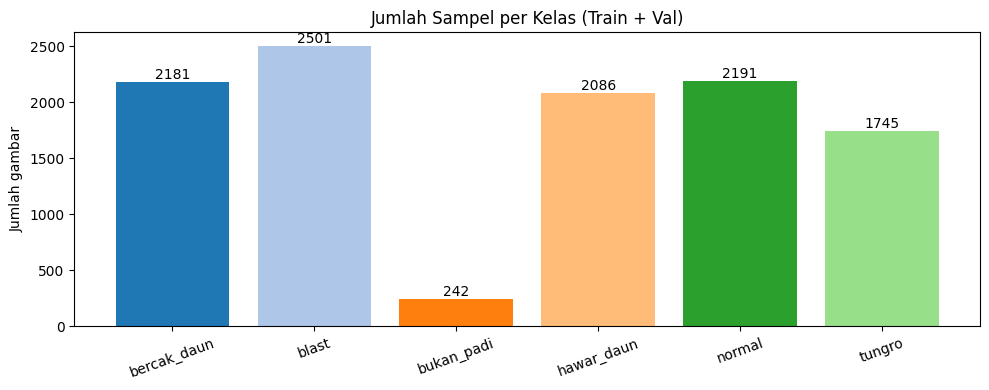

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def count_labels(ds):
    cnt = Counter()
    for _, y in ds.unbatch():
        cnt[int(y.numpy())] += 1
    return cnt

train_counts = count_labels(train_data)
val_counts   = count_labels(val_data)
all_counts   = {i: train_counts.get(i, 0) + val_counts.get(i, 0) for i in range(NUM_CLASSES)}

idx     = np.arange(NUM_CLASSES)
values  = [all_counts.get(i, 0) for i in range(NUM_CLASSES)]
colors  = plt.cm.tab20(idx % 20)   # warna-warni seperti contoh

plt.figure(figsize=(10, 4))
bars = plt.bar(idx, values, color=colors, edgecolor='none')

for b, v in zip(bars, values):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v}", ha='center', va='bottom', fontsize=10)

plt.xticks(idx, class_names, rotation=20)
plt.ylabel("Jumlah gambar")
plt.title("Jumlah Sampel per Kelas (Train + Val)")
plt.tight_layout()
plt.show()


In [ ]:

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomTranslation(height_factor=0.1, width_factor=0.1),
    RandomZoom(0.1),
    RandomBrightness(factor=0.15),
    RandomContrast(factor=0.15)
], name="rich_data_augmentation")

print("Lapisan augmentasi data telah dibuat.")

Lapisan augmentasi data telah dibuat.


In [ ]:
# ==============================================================================
# FUNGSI `build_model` 
# ==============================================================================

def build_model(optimizer_object): 
    """Membangun dan meng-compile model dengan OBJEK optimizer yang diberikan."""
    
    # 1. Muat model dasar EfficientNetV2B0
    base_model = EfficientNetV2B0(
        input_shape=IMAGE_SIZE + (3,),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False
    
    # 2. Buat arsitektur model baru
    inputs = Input(shape=IMAGE_SIZE + (3,), name="input_layer")
    x = data_augmentation(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax', name="output_layer")(x)
    
    model = Model(inputs, outputs)
    
    # 3. Compile model MENGGUNAKAN OBJEK OPTIMIZER YANG DIBERIKAN
    model.compile(
        optimizer=optimizer_object, 
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("Fungsi 'build_model' versi baru yang benar telah didefinisikan ulang.")

Fungsi 'build_model' versi baru yang benar telah didefinisikan ulang.



   UJI COBA OPTIMIZER: Adam
Memulai training dengan Adam untuk 15 epochs...

Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.6654 - loss: 0.9143
Epoch 1: val_loss improved from inf to 0.41299, saving model to checkpoints/best_rice_disease_model.keras

Epoch 1: val_loss did not improve from 0.41299
274/274 ━━━━━━━━━━━━━━━━━━━━ 195s 630ms/step - accuracy: 0.6658 - loss: 0.9134 - val_accuracy: 0.8817 - val_loss: 0.4130
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 616ms/step - accuracy: 0.8654 - loss: 0.4148
Epoch 2: val_loss improved from 0.41299 to 0.34585, saving model to checkpoints/best_rice_disease_model.keras

Epoch 2: val_loss did not improve from 0.34585
274/274 ━━━━━━━━━━━━━━━━━━━━ 199s 724ms/step - accuracy: 0.8654 - loss: 0.4148 - val_accuracy: 0.8785 - val_loss: 0.3459
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8852 - loss: 0.3365
Epoch 3: val_loss improved from 0.34585 to 0.30018, saving model to checkpoints/best_rice_disease_model.ker

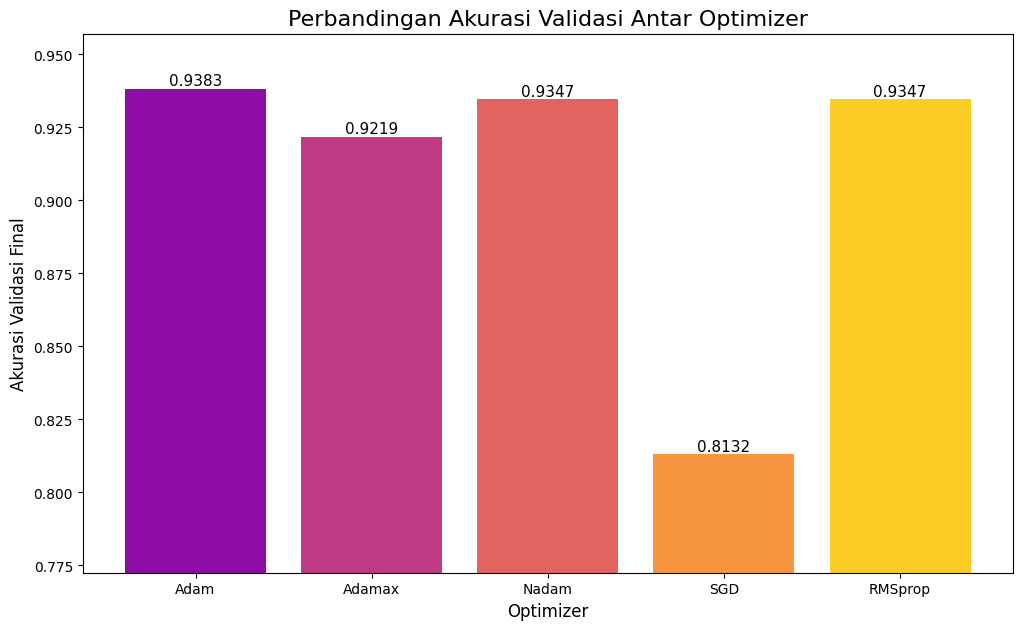


Optimizer terbaik adalah: Adam

   EVALUASI AKHIR PER OPTIMIZER (ACC, PREC, REC, F1, CM)
- Adam: Akurasi=0.9383 | Presisi=0.9525 | Recall=0.9503 | F1=0.9513


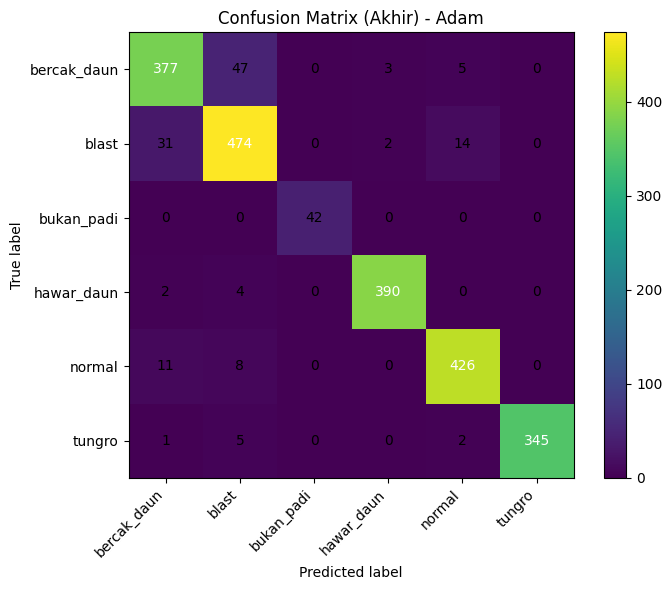

- Adamax: Akurasi=0.9219 | Presisi=0.9387 | Recall=0.9343 | F1=0.9361


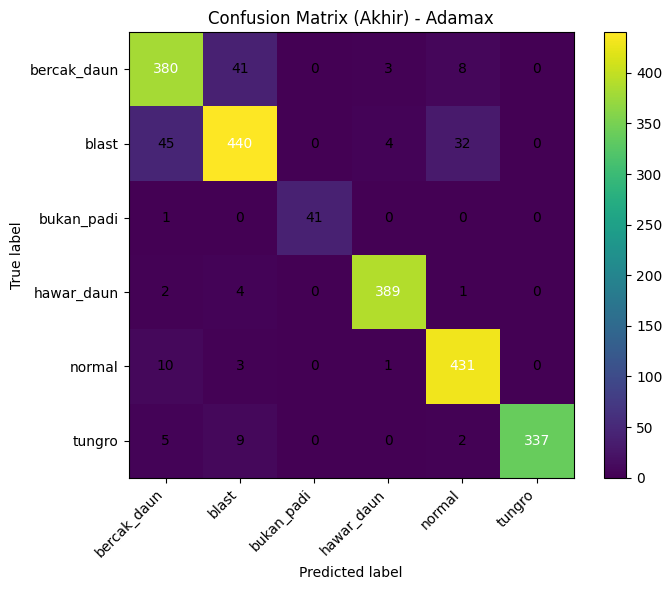

- Nadam: Akurasi=0.9347 | Presisi=0.9482 | Recall=0.9486 | F1=0.9482


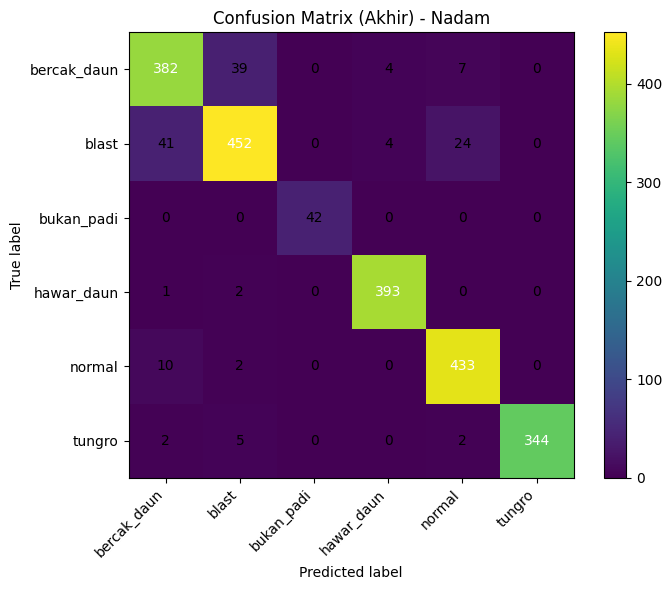

- SGD: Akurasi=0.8132 | Presisi=0.8487 | Recall=0.8237 | F1=0.8311


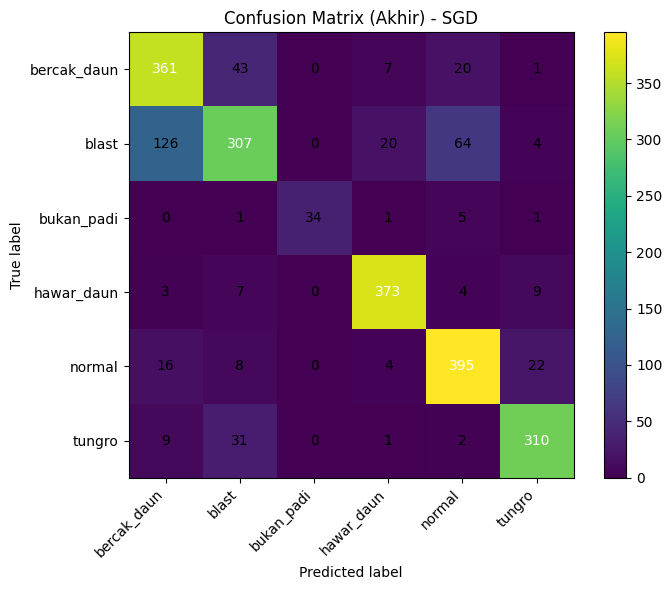

- RMSprop: Akurasi=0.9347 | Presisi=0.9498 | Recall=0.9469 | F1=0.9481


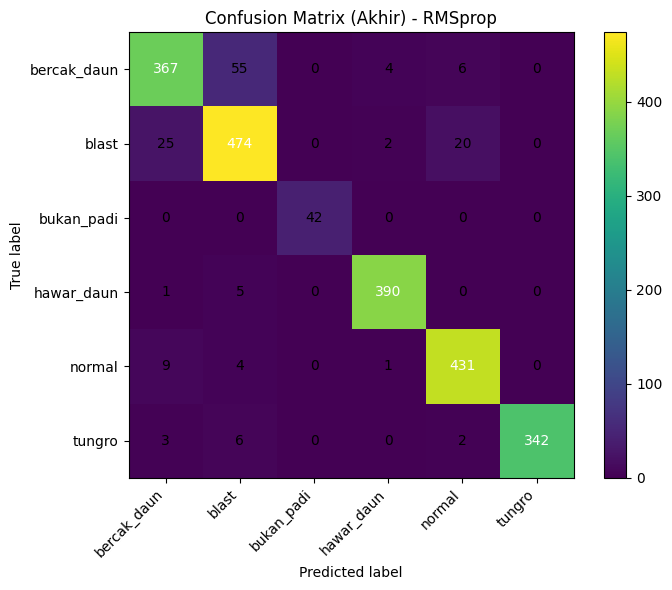

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# PERBANDINGAN OPTIMIZER + METRIK AKHIR (ACC, PREC, REC, F1) & CONFUSION MATRIX
# (Satu blok lengkap: tinggal tempel. Kode aslimu dipertahankan, hanya ada penambahan.)
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

# (opsional) jika val_data adalah tf.data.Dataset, agar bisa di-iterate berkali-kali:
# val_data = val_data.cache().prefetch(tf.data.AUTOTUNE)

# ── SIMPAN MODEL TERLATIH PER OPTIMIZER UNTUK DIEVALUASI SETELAH LOOP ──
trained_models = {}

# 1. Definisikan dictionary optimizer
optimizers_to_compare = {
    "Adam": Adam,
    "Adamax": Adamax,
    "Nadam": Nadam,
    "SGD": SGD,
    "RMSprop": RMSprop
}

# 2. Siapkan dictionary kosong untuk menyimpan hasil
results = {}

# 3. Loop utama untuk training dan evaluasi
for optimizer_name, optimizer_class in optimizers_to_compare.items():
    print(f"\n{'='*25}\n   UJI COBA OPTIMIZER: {optimizer_name}\n{'='*25}")
    
    # Buat instance dari optimizer dengan learning rate awal yang sama
    optimizer_instance = optimizer_class(learning_rate=0.001)
    
    # Bangun ulang model agar bobot reset
    model_experiment = build_model(optimizer_instance)
    
    print(f"Memulai training dengan {optimizer_name} untuk {EXPERIMENT_EPOCHS} epochs...\n")
    
    # Latih model dan tampilkan progress setiap epoch
    history = model_experiment.fit(
        train_data,
        validation_data=val_data,
        epochs=EXPERIMENT_EPOCHS,
        verbose=1  
    , callbacks=CALLBACKS)
    print("\nTraining selesai.")
    
    # Evaluasi model
    print(f"Evaluasi model dengan {optimizer_name}...")
    loss, accuracy = model_experiment.evaluate(val_data, verbose=0)
    print(f">>> Hasil {optimizer_name}: Akurasi Validasi = {accuracy:.4f}, Loss = {loss:.4f}")
    
    # (PENAMBAHAN) simpan model untuk evaluasi akhir setelah loop
    trained_models[optimizer_name] = model_experiment
    
    # Simpan hasil
    results[optimizer_name] = accuracy

# 4. Menampilkan hasil perbandingan
print(f"\n\n{'='*25}\n   HASIL AKHIR PERBANDINGAN OPTIMIZER\n{'='*25}")
sorted_results = sorted(results.items(), key=lambda item: item[1], reverse=True)

print("Peringkat Optimizer Berdasarkan Akurasi Validasi Tertinggi:")
for i, (optimizer_name, accuracy) in enumerate(sorted_results):
    print(f"{i+1}. {optimizer_name}: Akurasi = {accuracy:.4f}")
    
# Visualisasi hasil
plt.figure(figsize=(12, 7))
bars = plt.bar(list(results.keys()), list(results.values()), color=plt.cm.plasma(np.linspace(0.3, 0.9, len(results))))
plt.xlabel('Optimizer', fontsize=12)
plt.ylabel('Akurasi Validasi Final', fontsize=12)
plt.title('Perbandingan Akurasi Validasi Antar Optimizer', fontsize=16)
plt.ylim([min(results.values()) * 0.95, max(results.values()) * 1.02])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.4f}', va='bottom', ha='center', fontsize=11)

plt.show()

# Simpan nama optimizer terbaik
WINNING_OPTIMIZER_NAME = sorted_results[0][0]
print(f"\nOptimizer terbaik adalah: {WINNING_OPTIMIZER_NAME}")

# ─────────────────────────────────────────────────────────────────────────────
# EVALUASI AKHIR: CETAK AKURASI, PRESISI, RECALL, F1 (macro) + CONFUSION MATRIX
# untuk SETIAP OPTIMIZER, DIJALANKAN SETELAH LOOP (tanpa mengubah loop asli)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*25)
print("   EVALUASI AKHIR PER OPTIMIZER (ACC, PREC, REC, F1, CM)")
print("="*25)

# Ambil y_true sekali dari val_data (hemat waktu)
y_true = np.concatenate([y.numpy() for _, y in val_data], axis=0)
class_labels = list(class_names) if 'class_names' in globals() else [str(i) for i in sorted(np.unique(y_true))]
labels = list(range(len(class_labels)))

final_metrics = {}

for opt_name, model in trained_models.items():
    # Prediksi pada validation set
    y_proba = model.predict(val_data, verbose=0)
    y_pred  = np.argmax(y_proba, axis=1)

    # Skor akhir (macro)
    acc_final  = float((y_pred == y_true).mean())
    prec_final = float(precision_score(y_true, y_pred, average='macro',  zero_division=0))
    rec_final  = float(recall_score(  y_true, y_pred, average='macro',  zero_division=0))
    f1_final   = float(f1_score(      y_true, y_pred, average='macro',  zero_division=0))

    print(f"- {opt_name}: Akurasi={acc_final:.4f} | Presisi={prec_final:.4f} | "
          f"Recall={rec_final:.4f} | F1={f1_final:.4f}")

    # Confusion Matrix akhir
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7.5, 6.0))
    plt.imshow(cm, interpolation='nearest') 
    plt.title(f'Confusion Matrix (Akhir) - {opt_name}')
    plt.colorbar()
    tick_marks = np.arange(len(class_labels))
    plt.xticks(tick_marks, class_labels, rotation=45, ha='right')
    plt.yticks(tick_marks, class_labels)
    plt.xlabel('Predicted label')
    plt.ylabel('True label')

    # Tulis angka di tiap sel
    thresh = cm.max() / 2.0 if cm.size > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], 'd'),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black", fontsize=10)
    plt.tight_layout()
    plt.show()

    # Simpan ringkasan jika diperlukan
    final_metrics[opt_name] = {
        "accuracy": acc_final,
        "precision": prec_final,
        "recall": rec_final,
        "f1": f1_final,
        "cm": cm,
    }


In [ ]:
print("Memuat dataset...")
# Memuat data training (80% dari data)
train_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Memuat data validasi (20% dari data)
val_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Mengambil nama kelas dan jumlah kelas
class_names = train_data.class_names
NUM_CLASSES = len(class_names)
print(f"Ditemukan {NUM_CLASSES} kelas: {class_names}") 

# class_names sudah dari: class_names = train_data.class_names
label_to_index = {name: idx for idx, name in enumerate(class_names)}

import json, os
with open('class_indices.json', 'w') as f:
    json.dump(label_to_index, f)

print("Saved:", os.path.abspath('class_indices.json'))
print(label_to_index)


# Mengoptimalkan pipeline data untuk kecepatan
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
print("Dataset siap digunakan dan telah dioptimalkan.")

Memuat dataset...
Found 10946 files belonging to 6 classes.
Using 8757 files for training.
Found 10946 files belonging to 6 classes.
Using 2189 files for validation.
Ditemukan 6 kelas: ['bercak_daun', 'blast', 'bukan_padi', 'hawar_daun', 'normal', 'tungro']
Saved: c:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\class_indices.json
{'bercak_daun': 0, 'blast': 1, 'bukan_padi': 2, 'hawar_daun': 3, 'normal': 4, 'tungro': 5}
Dataset siap digunakan dan telah dioptimalkan.


In [11]:
print(f"\n--- Membangun model final dengan optimizer terbaik: {WINNING_OPTIMIZER_NAME} ---")

# Ambil kelas optimizer pemenang dari dictionary
winning_optimizer_class = optimizers_to_compare[WINNING_OPTIMIZER_NAME]
model = build_model(winning_optimizer_class(learning_rate=0.001))

model.summary()

# 6.1. Pelatihan Awal
print(f"\nMemulai pelatihan awal untuk {INITIAL_EPOCHS} epochs...")
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=INITIAL_EPOCHS
, callbacks=CALLBACKS)
print("\nPelatihan awal selesai.")

# 6.2. Fine-Tuning
print("\n--- Memulai Proses Fine-Tuning ---")
base_model = model.get_layer('efficientnetv2-b0')
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=winning_optimizer_class(learning_rate=1e-5), 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model telah di-compile ulang untuk fine-tuning.")

total_epochs = INITIAL_EPOCHS + FINE_TUNE_EPOCHS
history_fine = model.fit(
    train_data,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1],
    validation_data=val_data
, callbacks=CALLBACKS)
print("\nProses Fine-tuning selesai.")


--- Membangun model final dengan optimizer terbaik: Adam ---


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rich_data_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,926,998 (22.61 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)


Memulai pelatihan awal untuk 15 epochs...
Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.6452 - loss: 0.9510
Epoch 1: val_loss did not improve from 0.17387

Epoch 1: val_loss did not improve from 0.17387
274/274 ━━━━━━━━━━━━━━━━━━━━ 182s 626ms/step - accuracy: 0.6457 - loss: 0.9501 - val_accuracy: 0.8739 - val_loss: 0.4309
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8571 - loss: 0.4190
Epoch 2: val_loss did not improve from 0.17387

Epoch 2: val_loss did not improve from 0.17387
274/274 ━━━━━━━━━━━━━━━━━━━━ 164s 599ms/step - accuracy: 0.8571 - loss: 0.4189 - val_accuracy: 0.8954 - val_loss: 0.3413
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step - accuracy: 0.8890 - loss: 0.3365
Epoch 3: val_loss did not improve from 0.17387

Epoch 3: val_loss did not improve from 0.17387
274/274 ━━━━━━━━━━━━━━━━━━━━ 164s 598ms/step - accuracy: 0.8890 - loss: 0.3365 - val_accuracy: 0.9045 - val_loss: 0.2935
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 49


--- Memulai Evaluasi Model Final ---


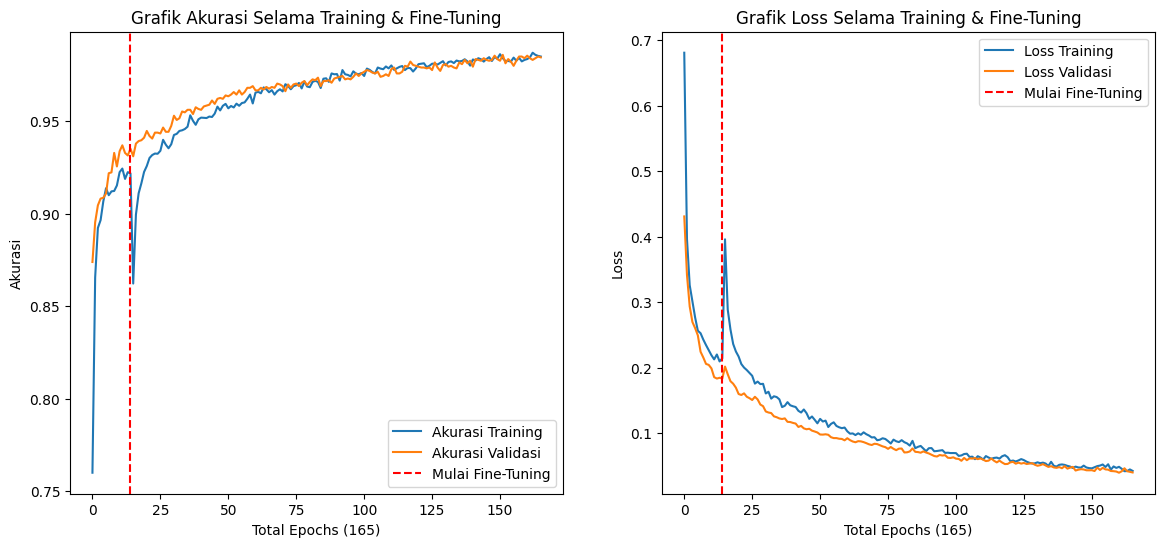


--- Mempersiapkan Matriks Evaluasi pada Data Validasi ---
69/69 ━━━━━━━━━━━━━━━━━━━━ 35s 386ms/step

--- Confusion Matrix ---


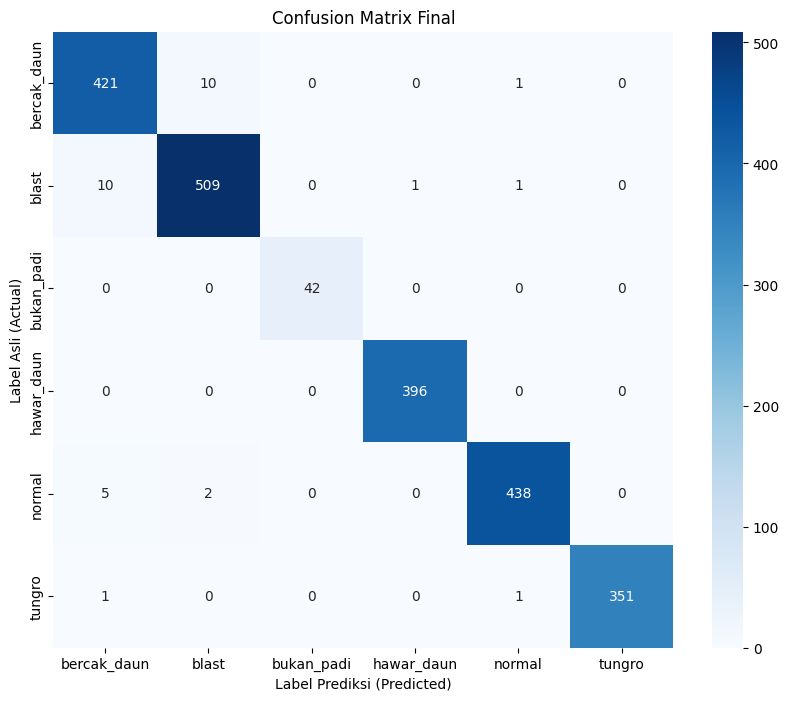


--- Laporan Klasifikasi Final ---
              precision    recall  f1-score   support

 bercak_daun       0.96      0.97      0.97       432
       blast       0.98      0.98      0.98       521
  bukan_padi       1.00      1.00      1.00        42
  hawar_daun       1.00      1.00      1.00       396
      normal       0.99      0.98      0.99       445
      tungro       1.00      0.99      1.00       353

    accuracy                           0.99      2189
   macro avg       0.99      0.99      0.99      2189
weighted avg       0.99      0.99      0.99      2189


--- Contoh Hasil Prediksi pada Data Validasi ---


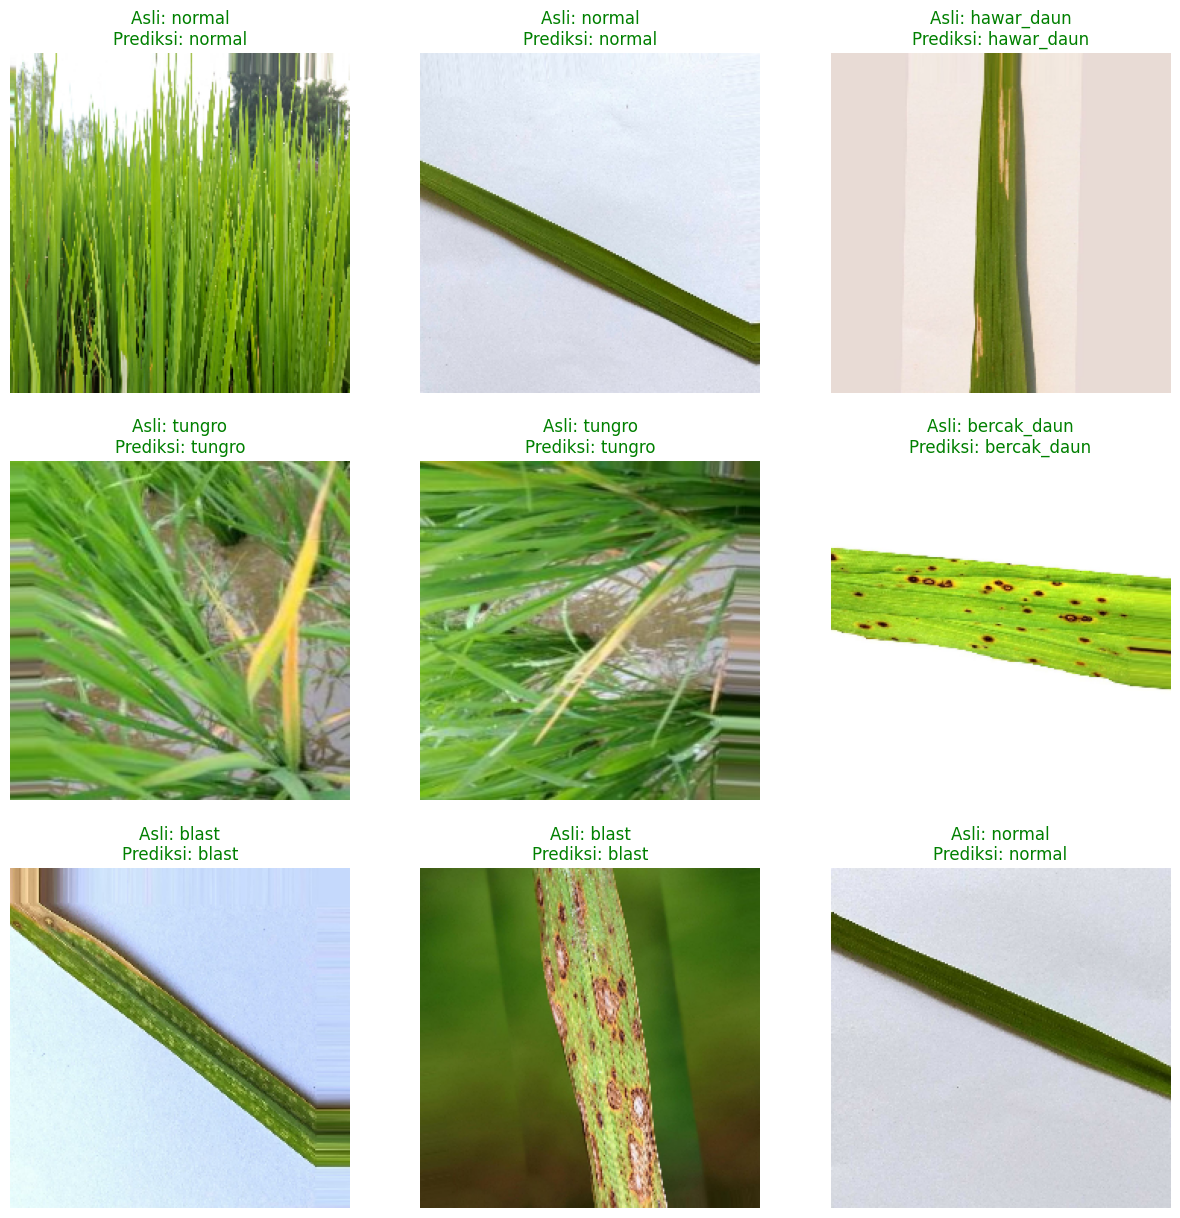

In [12]:
print("\n--- Memulai Evaluasi Model Final ---")


acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Akurasi Training')
plt.plot(val_acc, label='Akurasi Validasi')
plt.axvline(INITIAL_EPOCHS -1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Selama Training & Fine-Tuning')
plt.xlabel(f'Total Epochs ({total_epochs})')
plt.ylabel('Akurasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Loss Training')
plt.plot(val_loss, label='Loss Validasi')
plt.axvline(INITIAL_EPOCHS - 1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='upper right')
plt.title('Grafik Loss Selama Training & Fine-Tuning')
plt.xlabel(f'Total Epochs ({total_epochs})')
plt.ylabel('Loss')
plt.show()

# 7.2. Matriks Evaluasi Detail
print("\n--- Mempersiapkan Matriks Evaluasi pada Data Validasi ---")
predictions = model.predict(val_data)
y_pred = np.argmax(predictions, axis=1)
y_true = np.concatenate([y for x, y in val_data], axis=0)

# Confusion Matrix
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Final')
plt.ylabel('Label Asli (Actual)')
plt.xlabel('Label Prediksi (Predicted)')
plt.show()

# Laporan Klasifikasi
print("\n--- Laporan Klasifikasi Final ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 7.3 Visualisasi Prediksi
print("\n--- Contoh Hasil Prediksi pada Data Validasi ---")
plt.figure(figsize=(15, 15))
for images, labels in val_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        actual_label = class_names[labels[i]]
        predicted_label = class_names[y_pred[i]] # Ambil dari y_pred yang sudah dihitung
        
        title_color = 'green' if actual_label == predicted_label else 'red'
        plt.title(f"Asli: {actual_label}\nPrediksi: {predicted_label}", color=title_color)
        plt.axis("off")
plt.show()

In [ ]:
# ==============================================================================
# BAGIAN 8: MENYIMPAN DAN MENGGUNAKAN MODEL FINAL (VERSI PERBAIKAN FINAL)
# ==============================================================================

# 8.1 Menyimpan Model Final dengan Format .keras
MODEL_FILENAME = "model_penyakit_padi_final2.keras"
model.save(MODEL_FILENAME)

print(f"Model final telah disimpan dengan nama: {MODEL_FILENAME}")

print("\nMemuat kembali model dari file .keras...")

loaded_model = tf.keras.models.load_model(MODEL_FILENAME)
print("Model berhasil dimuat.")
# Verifikasi model yang dimuat
loaded_model.summary()


def prediksi_gambar(path_gambar, model_yang_dimuat):
    """Fungsi untuk memprediksi kelas dari satu file gambar."""
    img = tf.keras.utils.load_img(path_gambar, target_size=IMAGE_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) 

    predictions = model_yang_dimuat.predict(img_array)
    score = tf.nn.softmax(predictions[0])
    
    pred_class = class_names[np.argmax(score)]
    confidence = 100 * np.max(score)

    print(f"\nGambar: {os.path.basename(path_gambar)}")
    print(f"Hasil Prediksi: {pred_class}")
    print(f"Tingkat Keyakinan: {confidence:.2f}%")
    
    plt.imshow(img)
    plt.axis('off')
    plt.show()



Model final telah disimpan dengan nama: model_penyakit_padi_final2.keras

Memuat kembali model dari file .keras...
Model berhasil dimuat.


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rich_data_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,578,052 (28.91 MB)

 Trainable params: 825,526 (3.15 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

 Optimizer params: 1,651,054 (6.30 MB)

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# ==============================================================================
# 1. KONFIGURASI DAN MEMUAT MODEL
# ==============================================================================


IMAGE_SIZE = (224, 224)
MODEL_FILENAME = "model_penyakit_padi_final2.keras" 


try:
    class_names
except NameError:
    print("Variabel 'class_names' tidak ditemukan, mengambil ulang dari direktori...")
    class_names = sorted(os.listdir(DATA_DIR))
    print(f"Kelas ditemukan: {class_names}")


# Memuat model yang sudah terlatih
print(f"Memuat model dari file: {MODEL_FILENAME}...")
try:
    loaded_model = tf.keras.models.load_model(MODEL_FILENAME)
    print("Model berhasil dimuat.")
except Exception as e:
    print(f"Gagal memuat model. Error: {e}")
    assert False, "Periksa kembali nama file model Anda."


Memuat model dari file: model_penyakit_padi_final2.keras...
Model berhasil dimuat.


In [7]:
# UTILITAS GRAD-CAM (versi aman)
def _find_gap_layer(model):
    import tensorflow as tf
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D):
            return layer
    raise ValueError("Tidak menemukan GlobalAveragePooling2D.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name=None, gap_layer_name="global_average_pooling2d_5", pred_index=None):
    import tensorflow as tf
    if last_conv_layer_name is None:
        gap_layer = model.get_layer(gap_layer_name)
        target_tensor = gap_layer.input              
    else:
        
        target_tensor = model.get_layer(last_conv_layer_name).output

    grad_model = tf.keras.models.Model(model.inputs, [target_tensor, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-12)
    return heatmap.numpy()


from matplotlib import cm
def overlay_heatmap_on_image(pil_img, heatmap, alpha=0.45, image_size=None):
    if image_size is None:
        image_size = pil_img.size[::-1]
    heatmap_uint8 = np.uint8(255 * heatmap)
    jet = cm.get_cmap('jet')
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_uint8]
    jet_heatmap = tf.image.resize(jet_heatmap, image_size).numpy()
    base = np.array(pil_img).astype(np.float32)
    jet_heatmap_255 = (jet_heatmap * 255.0).astype(np.float32)
    superimposed = np.clip(base * (1 - alpha) + jet_heatmap_255 * alpha, 0, 255).astype(np.uint8)
    return superimposed


In [8]:
# ==============================================================================
# FUNGSI PREDIKSI & TAMPILKAN GRAD-CAM
# ==============================================================================
def prediksi_gambar(
    path_gambar,
    model_yang_dimuat,
    last_conv_layer_name=None,  
    alpha_overlay=0.45,
    save_to=None,
    show=True
):
    print("-" * 30)
    # 1) Load & siapkan gambar
    img = tf.keras.utils.load_img(path_gambar, target_size=IMAGE_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, 0)  # (1, H, W, 3)

    # 2) Prediksi
    preds = model_yang_dimuat.predict(img_batch)
    probs = tf.nn.softmax(preds[0]).numpy()
    pred_idx = int(np.argmax(probs))
    pred_class = class_names[pred_idx]

    # 3) Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array=img_batch,
        model=model_yang_dimuat,
        last_conv_layer_name=last_conv_layer_name,   
        gap_layer_name="global_average_pooling2d_5",
        pred_index=pred_idx
    )

    # 4) Overlay heatmap
    overlay = overlay_heatmap_on_image(
        pil_img=img, heatmap=heatmap, alpha=alpha_overlay, image_size=IMAGE_SIZE
    )


    # 6) Output ringkas
    print(f"Gambar: {os.path.basename(path_gambar)}")
    print(f"Hasil Prediksi: '{pred_class}'")
    
    

    # 7) Tampilkan
    if show:
        plt.figure(figsize=(12,6))
        plt.subplot(1,2,1); plt.imshow(img); plt.title(f"Asli\n{pred_class}"); plt.axis('off')
        plt.subplot(1,2,2); plt.imshow(overlay); plt.title("Grad-CAM Overlay"); plt.axis('off')
        plt.tight_layout(); plt.show()

    print("-" * 30)
    


------------------------------
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


C:\Users\abima\AppData\Local\Temp\ipykernel_3408\1545801378.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap('jet')


Gambar: bunga.jpg
Hasil Prediksi: 'bukan_padi'


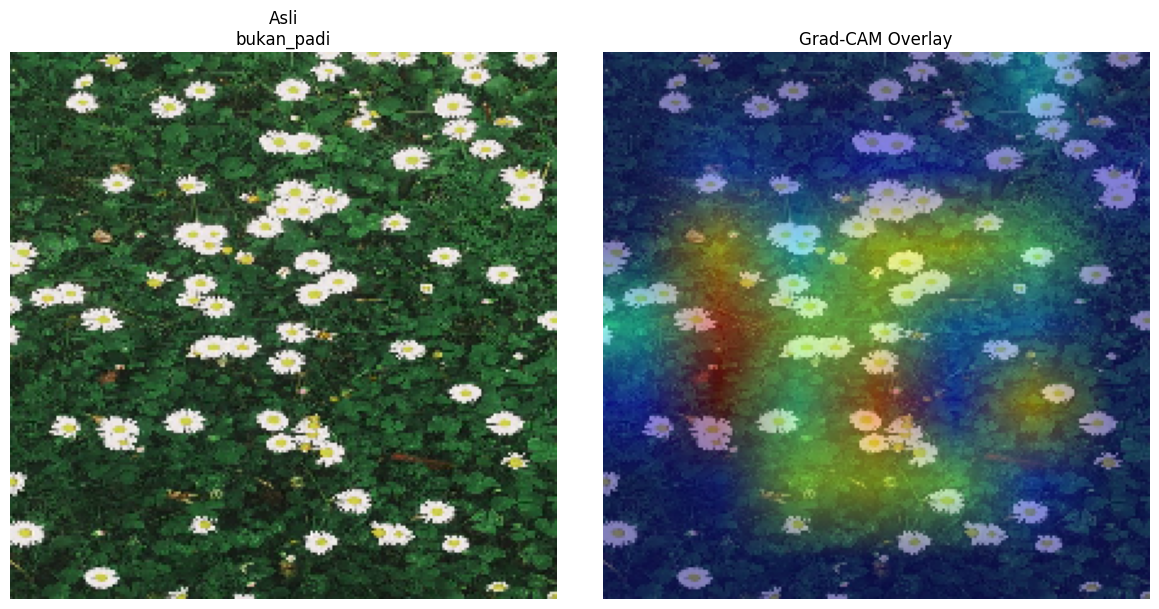

------------------------------
None


In [9]:
PATH_GAMBAR_UJI = r"C:\Users\abima\OneDrive\Documents\SKRIPSI\SEMHAS\bunga.jpg"

if os.path.exists(PATH_GAMBAR_UJI):
    hasil = prediksi_gambar(
        PATH_GAMBAR_UJI,
        loaded_model,
        alpha_overlay=0.45,
        save_to=None,  
        show=True
    )
    print(hasil)
else:
    print(f"ERROR: File tidak ditemukan di path: {PATH_GAMBAR_UJI}")
    print(r"Mohon periksa kembali path file gambar Anda")
